# Загрузка и подготовка датасета для обучения

In [ ]:
import kagglehub
from kagglehub import KaggleDatasetAdapter
import os
import pandas as pd
from sklearn.model_selection import train_test_split
import time
from catboost import CatBoostClassifier
from sklearn.metrics import f1_score
import time, json
import numpy as np
from scipy.stats import norm
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel
from sklearn.preprocessing import StandardScaler
import optuna
from sklearn.pipeline import make_pipeline

114000 Spotify Songs - набор данных, который содержит информацию о треках из Spotify. Каждый трек характеризуется набором аудиопараметров и метаданных

In [ ]:
path = kagglehub.dataset_download("priyamchoksi/spotify-dataset-114k-songs")
print(os.listdir(path))

100%|██████████| 8.17M/8.17M [00:00<00:00, 56.0MB/s]

Extracting files...


['dataset.csv']


In [ ]:
df = pd.read_csv(os.path.join(path, "dataset.csv"))

In [ ]:
df

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.7150,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.2670,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.1200,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.1430,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.1670,119.949,4,acoustic
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113995,113995,2C3TZjDRiAzdyViavDJ217,Rainy Lullaby,#mindfulness - Soft Rain for Mindful Meditatio...,Sleep My Little Boy,21,384999,False,0.172,0.2350,...,-16.393,1,0.0422,0.6400,0.928000,0.0863,0.0339,125.995,5,world-music
113996,113996,1hIz5L4IB9hN3WRYPOCGPw,Rainy Lullaby,#mindfulness - Soft Rain for Mindful Meditatio...,Water Into Light,22,385000,False,0.174,0.1170,...,-18.318,0,0.0401,0.9940,0.976000,0.1050,0.0350,85.239,4,world-music
113997,113997,6x8ZfSoqDjuNa5SVP5QjvX,Cesária Evora,Best Of,Miss Perfumado,22,271466,False,0.629,0.3290,...,-10.895,0,0.0420,0.8670,0.000000,0.0839,0.7430,132.378,4,world-music
113998,113998,2e6sXL2bYv4bSz6VTdnfLs,Michael W. Smith,Change Your World,Friends,41,283893,False,0.587,0.5060,...,-10.889,1,0.0297,0.3810,0.000000,0.2700,0.4130,135.960,4,world-music


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  object 
 2   artists           113999 non-null  object 
 3   album_name        113999 non-null  object 
 4   track_name        113999 non-null  object 
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          11

In [ ]:
df['track_id'].duplicated().sum()

np.int64(24259)

In [ ]:
df = df.drop_duplicates(subset='track_id', keep='first').reset_index(drop=True)
df.shape, df['track_genre'].nunique()

((89741, 21), 113)

In [ ]:
counts = df["track_genre"].value_counts()

for thr in [990, 950, 900, 850, 800]:
    print(f"≥{thr} наблюдений: {(counts >= thr).sum()} жанров")

≥990 наблюдений: 21 жанров
≥950 наблюдений: 33 жанров
≥900 наблюдений: 51 жанров
≥850 наблюдений: 61 жанров
≥800 наблюдений: 71 жанров


In [ ]:
counts.head(10)

,count
track_genre,
acoustic,1000
afrobeat,999
alt-rock,999
ambient,999
cantopop,999
tango,999
chicago-house,998
forro,998
bluegrass,998


Таргет - track_genre (всего получилось 113 классов, но возьмем только топ-10 по числу уникальных треков после удаления дубликатов, чтобы сэкономить время)

Аудио-фичи: danceability, energy, loudness, speechiness, acousticness, instrumentalness, liveness, valence, tempo, duration_ms, popularity непрерывные

Категориальные: key, mode, time_signature, explicit можно передать в CatBoost как cat_features

Unnamed: 0, track_id, artists, album_name, track_name — служебные/идентификаторы, можно удалить

In [ ]:
spotify_df = df.drop(columns=["Unnamed: 0", "track_id", "artists", "album_name", "track_name"])
spotify_df

,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.7150,87.917,4,acoustic
1,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.2670,77.489,4,acoustic
2,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.1200,76.332,4,acoustic
3,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.1430,181.740,3,acoustic
4,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.1670,119.949,4,acoustic
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
89736,21,384999,False,0.172,0.2350,5,-16.393,1,0.0422,0.6400,0.928000,0.0863,0.0339,125.995,5,world-music
89737,22,385000,False,0.174,0.1170,0,-18.318,0,0.0401,0.9940,0.976000,0.1050,0.0350,85.239,4,world-music
89738,22,271466,False,0.629,0.3290,0,-10.895,0,0.0420,0.8670,0.000000,0.0839,0.7430,132.378,4,world-music
89739,41,283893,False,0.587,0.5060,7,-10.889,1,0.0297,0.3810,0.000000,0.2700,0.4130,135.960,4,world-music


In [ ]:
spotify_df['explicit'] = spotify_df['explicit'].astype(int)

In [ ]:
top_genres = spotify_df["track_genre"].value_counts().head(10).index
spotify_df = spotify_df[spotify_df["track_genre"].isin(top_genres)].reset_index(drop=True)

cat_features = ["key", "mode", "time_signature", "explicit"]
feature_cols = ["danceability","energy","loudness","speechiness","acousticness",
                "instrumentalness","liveness","valence","tempo","duration_ms",
                "popularity"] + cat_features

In [ ]:
X = spotify_df[feature_cols]
y = spotify_df["track_genre"]

print(X.shape, y.nunique())
print(y.value_counts())

(9987, 15) 10
track_genre
acoustic         1000
afrobeat          999
alt-rock          999
ambient           999
cantopop          999
tango             999
bluegrass         998
chicago-house     998
forro             998
study             998
Name: count, dtype: int64


In [ ]:
X_trainval, X_test, y_trainval, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

X_train, X_val, y_train, y_val = train_test_split(X_trainval, y_trainval, test_size=0.25, stratify=y_trainval, random_state=42)

print(X_train.shape, X_val.shape, X_test.shape)

(5991, 15) (1998, 15) (1998, 15)


# Определение гиперпараметров и их границ

In [ ]:
SPACE = {
    "iterations":                 (100, 500, "int"),
    "learning_rate":              (0.01, 0.3, "log"),
    "depth":                      (4, 8, "int"),
    "l2_leaf_reg":                (1.0, 20.0, "log"),
    "random_strength":            (0.1, 10.0, "log"),
    "border_count":               (32, 255, "int"),
    "rsm":                        (0.3, 1.0, "float"),
    "model_size_reg":             (0.0, 5.0, "float"),
    "leaf_estimation_iterations": (1, 10, "int"),
    "one_hot_max_size":           (2, 16, "int"),
    "max_ctr_complexity":         (1, 4, "int"),
    "bootstrap_type":      ["Bayesian", "Bernoulli", "MVS"],
    "grow_policy":         ["SymmetricTree", "Depthwise", "Lossguide"],
    "boosting_type":       ["Plain", "Ordered"],
    "feature_border_type": ["GreedyLogSum", "Median", "Uniform", "UniformAndQuantiles", "MaxLogSum", "MinEntropy"],
    "sampling_frequency":  ["PerTree", "PerTreeLevel"],
    "bagging_temperature": (0.0, 1.0, "float"),
    "subsample":           (0.5, 1.0, "float"),
    "min_data_in_leaf":    (1, 50, "int"),
    "max_leaves":          (8, 64, "int"),
}

def is_active(name, cfg):
    if name == "bagging_temperature": return cfg["bootstrap_type"] == "Bayesian"
    if name == "subsample":           return cfg["bootstrap_type"] in ("Bernoulli", "MVS")
    if name == "min_data_in_leaf":    return cfg["grow_policy"] in ("Depthwise", "Lossguide")
    if name == "max_leaves":          return cfg["grow_policy"] == "Lossguide"
    if name == "boosting_type":       return cfg["grow_policy"] == "SymmetricTree"
    if name == "sampling_frequency":  return cfg["grow_policy"] != "Lossguide"
    return True

def sample_one(spec, rng):
    if isinstance(spec, list):
        return spec[rng.integers(len(spec))]
    lo, hi, kind = spec
    if kind == "log": return float(np.exp(rng.uniform(np.log(lo), np.log(hi))))
    if kind == "int": return int(rng.integers(lo, hi + 1))
    return float(rng.uniform(lo, hi))

def sample_config(rng):
    cfg = {n: sample_one(s, rng) for n, s in SPACE.items()}
    return {k: v for k, v in cfg.items() if is_active(k, cfg)}   # неактивные выбрасываем

In [ ]:
# целевая функция
def evaluate(cfg):
    m = CatBoostClassifier(**cfg, cat_features=cat_features,
                           thread_count=-1, random_seed=42, verbose=0)
    m.fit(X_train, y_train)
    return f1_score(y_val, m.predict(X_val).ravel(), average="macro")

Macro-F1 была выбрана как стандартная метрика для многоклассовой классификации, одинаково учитывающая все классы (здесь классы сбалансированы, поэтому она близка к accuracy)

# Случайный поиск

In [ ]:
def run_random(n_steps, seed=0, path="results_random.json"):
    rng = np.random.default_rng(seed)
    history = []
    for i in range(n_steps):
        cfg = sample_config(rng)
        t = time.time()
        try:
            score = float(evaluate(cfg))
        except Exception as e:
            print(f"  ошибка на шаге {i}: {str(e)[:100]}")
            score = 0.0
        history.append({"step": i, "cfg": cfg, "score": score, "time": time.time() - t})
        with open(path, "w") as f:
            json.dump(history, f)
        print(f"{i:3d} | macro-F1={score:.4f} | best={max(h['score'] for h in history):.4f} | {history[-1]['time']:.0f} с")
    return history

In [ ]:

import os
SAVE_DIR = "results/bayes_opt"  # путь относительно папки automl
os.makedirs(SAVE_DIR, exist_ok=True)

SEEDS = [0, 1, 2]
hist_random = {}
for s in SEEDS:
    hist_random[s] = run_random(40, seed=s, path=f"{SAVE_DIR}/results_random_seed{s}.json")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
  0 | macro-F1=0.8076 | best=0.8076 | 25 с
  1 | macro-F1=0.8101 | best=0.8101 | 48 с
  2 | macro-F1=0.8084 | best=0.8101 | 21 с
  3 | macro-F1=0.8058 | best=0.8101 | 57 с
  4 | macro-F1=0.7696 | best=0.8101 | 50 с
  5 | macro-F1=0.7967 | best=0.8101 | 37 с
  6 | macro-F1=0.8070 | best=0.8101 | 33 с
  7 | macro-F1=0.8161 | best=0.8161 | 119 с
  8 | macro-F1=0.8120 | best=0.8161 | 36 с
  9 | macro-F1=0.8046 | best=0.8161 | 23 с
 10 | macro-F1=0.8106 | best=0.8161 | 121 с
 11 | macro-F1=0.8107 | best=0.8161 | 10 с
 12 | macro-F1=0.8063 | best=0.8161 | 29 с
 13 | macro-F1=0.8229 | best=0.8229 | 207 с
 14 | macro-F1=0.7891 | best=0.8229 | 26 с
 15 | macro-F1=0.7755 | best=0.8229 | 14 с
 16 | macro-F1=0.8093 | best=0.8229 | 73 с
 17 | macro-F1=0.8029 | best=0.8229 | 13 с
 18 | macro-F1=0.8130 | best=0.8229 | 172 с
 19 | macro-F1=0.7341 | best=0.8229 | 49 с
 20 | m

# Алгоритм байесовской оптимизации

*Суррогат*

Random Forest работает с категориальными и условными параметрами

*Инициализация*

1. Сгенерировать 8 случайных конфигураций, чтобы Random Forest мог найти в них структуру (те же, что у случайного поиска с тем же сидом).
2. Посчитать для них реальное качество yᵢ = f(xᵢ) — функция evaluate (macro-F1 на val).
3. Обучить суррогат на D = {(xᵢ, yᵢ)}.

*Каждая итерация*

1. Найти x, максимизирующий функцию улучшения.
2. Посчитать для него реальное y = f(x).
3. Добавить (x, y) в D.
4. Переобучить суррогат.

*Функция улучшения*

EI (Expected Improvement)

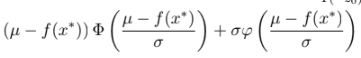

*Поиск максимума EI*

Пространство смешанное (категориальные и условные параметры), градиентная максимизация неприменима. Максимум ищется приближенно: генерируются 3000 случайных допустимых конфигураций (sample_config), для каждой считается EI, выбирается лучшая

In [ ]:
def expected_improvement(mu, sigma, f_best, xi=0.0):
    sigma = np.maximum(sigma, 1e-9)
    z = (mu - f_best - xi) / sigma
    return (mu - f_best - xi) * norm.cdf(z) + sigma * norm.pdf(z)

*Кодирование конфигурации в вектор*

Числа берутся как есть, категории заменяются номером, неактивные условные параметры получают −1 (все допустимые значения ≥ 0, поэтому −1 однозначен)

In [ ]:
NAMES = list(SPACE.keys())

def encode(cfg):
    v = []
    for n in NAMES:
        if n not in cfg:
            v.append(-1.0)   # неактивный параметр
        elif isinstance(SPACE[n], list):
            v.append(float(SPACE[n].index(cfg[n])))
        else:
          v.append(float(cfg[n]))
    return v

*Параметры реализации*

бюджет 40 шагов, из них 8 случайных (20%). Число начальных точек выбрано эвристически, чувствительность к нему не исследовалась. Random Forest: 100 деревьев. Параметр сдвига в EI равен 0

In [ ]:
def rf_predict(rf, X):
    p = np.stack([t.predict(X) for t in rf.estimators_])   # (деревья, кандидаты)
    return p.mean(0), p.std(0)

def run_bo(n_steps=40, n_init=8, seed=0, n_cand=3000, path=None, init_hist=None):
    rng = np.random.default_rng(seed)                  # тот же поток, что у random search
    cand_rng = np.random.default_rng(10_000 + seed)    # отдельный поток для кандидатов
    history = []
    for i in range(n_steps):
        if init_hist is not None and i < n_init:
            history.append(init_hist[i]); continue     # готовый результат random search
        if i < n_init:
            cfg = sample_config(rng)
        else:
            X_h = np.array([encode(h["cfg"]) for h in history])
            y_h = np.array([h["score"] for h in history])
            rf = RandomForestRegressor(n_estimators=100, random_state=seed).fit(X_h, y_h)
            cands = [sample_config(cand_rng) for _ in range(n_cand)]
            mu, sigma = rf_predict(rf, np.array([encode(c) for c in cands]))
            cfg = cands[int(np.argmax(expected_improvement(mu, sigma, y_h.max())))]
        t = time.time()
        try:
            score = float(evaluate(cfg))
        except Exception as e:
            print(f"  ошибка на шаге {i}: {str(e)[:100]}"); score = 0.0
        history.append({"step": i, "cfg": cfg, "score": score, "time": time.time() - t})
        if path:
            with open(path, "w") as f: json.dump(history, f)
        print(f"{i:3d} | {'init' if i < n_init else 'BO  '} | macro-F1={score:.4f} | best={max(h['score'] for h in history):.4f} | {history[-1]['time']:.0f} с")
    return history

In [ ]:
SEEDS = [0, 1, 2]

import os
SAVE_DIR = "results/bayes_opt"  # путь относительно папки automl
os.makedirs(SAVE_DIR, exist_ok=True)
hist_random = {s: json.load(open(f"{SAVE_DIR}/results_random_seed{s}.json")) for s in SEEDS}

Mounted at /content/drive


In [ ]:
hist_bo = {}
hist_bo[0] = run_bo(40, n_init=8, seed=0, path=f"{SAVE_DIR}/results_bo_seed0.json", init_hist=hist_random[0])

  8 | BO   | macro-F1=0.8167 | best=0.8167 | 68 с
  9 | BO   | macro-F1=0.8190 | best=0.8190 | 121 с
 10 | BO   | macro-F1=0.8134 | best=0.8190 | 8 с
 11 | BO   | macro-F1=0.8244 | best=0.8244 | 64 с
 12 | BO   | macro-F1=0.7314 | best=0.8244 | 8 с
 13 | BO   | macro-F1=0.8109 | best=0.8244 | 14 с
 14 | BO   | macro-F1=0.8194 | best=0.8244 | 87 с
 15 | BO   | macro-F1=0.7328 | best=0.8244 | 38 с
 16 | BO   | macro-F1=0.7765 | best=0.8244 | 20 с
 17 | BO   | macro-F1=0.8137 | best=0.8244 | 111 с
 18 | BO   | macro-F1=0.8188 | best=0.8244 | 83 с
 19 | BO   | macro-F1=0.8096 | best=0.8244 | 68 с
 20 | BO   | macro-F1=0.7951 | best=0.8244 | 14 с
 21 | BO   | macro-F1=0.8107 | best=0.8244 | 31 с
 22 | BO   | macro-F1=0.8155 | best=0.8244 | 229 с
 23 | BO   | macro-F1=0.8179 | best=0.8244 | 72 с
 24 | BO   | macro-F1=0.8084 | best=0.8244 | 11 с
 25 | BO   | macro-F1=0.8118 | best=0.8244 | 24 с
 26 | BO   | macro-F1=0.8023 | best=0.8244 | 59 с
 27 | BO   | macro-F1=0.8222 | best=0.8244 | 36 с

In [ ]:
hist_bo[1] = run_bo(40, n_init=8, seed=1, path=f"{SAVE_DIR}/results_bo_seed1.json", init_hist=hist_random[1])

  8 | BO   | macro-F1=0.8096 | best=0.8148 | 33 с
  9 | BO   | macro-F1=0.7948 | best=0.8148 | 15 с
 10 | BO   | macro-F1=0.8166 | best=0.8166 | 28 с
 11 | BO   | macro-F1=0.8097 | best=0.8166 | 45 с
 12 | BO   | macro-F1=0.8113 | best=0.8166 | 17 с
 13 | BO   | macro-F1=0.7988 | best=0.8166 | 27 с
 14 | BO   | macro-F1=0.8096 | best=0.8166 | 10 с
 15 | BO   | macro-F1=0.8053 | best=0.8166 | 32 с
 16 | BO   | macro-F1=0.7572 | best=0.8166 | 4 с
 17 | BO   | macro-F1=0.7709 | best=0.8166 | 11 с
 18 | BO   | macro-F1=0.8121 | best=0.8166 | 22 с
 19 | BO   | macro-F1=0.8082 | best=0.8166 | 9 с
 20 | BO   | macro-F1=0.8068 | best=0.8166 | 7 с
 21 | BO   | macro-F1=0.8063 | best=0.8166 | 14 с
 22 | BO   | macro-F1=0.8023 | best=0.8166 | 24 с
 23 | BO   | macro-F1=0.8044 | best=0.8166 | 14 с
 24 | BO   | macro-F1=0.8013 | best=0.8166 | 39 с
 25 | BO   | macro-F1=0.7651 | best=0.8166 | 3 с
 26 | BO   | macro-F1=0.8169 | best=0.8169 | 51 с
 27 | BO   | macro-F1=0.8160 | best=0.8169 | 34 с
 28 

In [ ]:
hist_bo[2] = run_bo(40, n_init=8, seed=2, path=f"{SAVE_DIR}/results_bo_seed2.json", init_hist=hist_random[2])

  8 | BO   | macro-F1=0.8164 | best=0.8169 | 56 с
  9 | BO   | macro-F1=0.8012 | best=0.8169 | 8 с
 10 | BO   | macro-F1=0.8132 | best=0.8169 | 73 с
 11 | BO   | macro-F1=0.8161 | best=0.8169 | 19 с
 12 | BO   | macro-F1=0.8120 | best=0.8169 | 45 с
 13 | BO   | macro-F1=0.7907 | best=0.8169 | 42 с
 14 | BO   | macro-F1=0.7644 | best=0.8169 | 24 с
 15 | BO   | macro-F1=0.6838 | best=0.8169 | 10 с
 16 | BO   | macro-F1=0.7895 | best=0.8169 | 102 с
 17 | BO   | macro-F1=0.8119 | best=0.8169 | 13 с
 18 | BO   | macro-F1=0.7967 | best=0.8169 | 38 с
 19 | BO   | macro-F1=0.8106 | best=0.8169 | 37 с
 20 | BO   | macro-F1=0.8149 | best=0.8169 | 27 с
 21 | BO   | macro-F1=0.8057 | best=0.8169 | 20 с
 22 | BO   | macro-F1=0.7504 | best=0.8169 | 132 с
 23 | BO   | macro-F1=0.8150 | best=0.8169 | 8 с
 24 | BO   | macro-F1=0.8063 | best=0.8169 | 7 с
 25 | BO   | macro-F1=0.8055 | best=0.8169 | 108 с
 26 | BO   | macro-F1=0.8082 | best=0.8169 | 8 с
 27 | BO   | macro-F1=0.7899 | best=0.8169 | 3 с
 2

In [ ]:
SEEDS = [0, 1, 2]
import os
SAVE_DIR = "results/bayes_opt"  # путь относительно папки automl
hist_random = {s: json.load(open(f"{SAVE_DIR}/results_random_seed{s}.json")) for s in SEEDS}
hist_bo     = {s: json.load(open(f"{SAVE_DIR}/results_bo_seed{s}.json")) for s in SEEDS}
hist_gp     = {s: json.load(open(f"{SAVE_DIR}/results_gp_seed{s}.json")) for s in SEEDS}
hist_optuna_tpe  = {s: json.load(open(f"{SAVE_DIR}/results_optuna_tpe_seed{s}.json")) for s in SEEDS}
hist_optuna_rand = {s: json.load(open(f"{SAVE_DIR}/results_optuna_random_seed{s}.json")) for s in SEEDS}
hist_random_small = json.load(open(f"{SAVE_DIR}/results_random_small.json"))
hist_bo_small     = json.load(open(f"{SAVE_DIR}/results_bo_small.json"))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


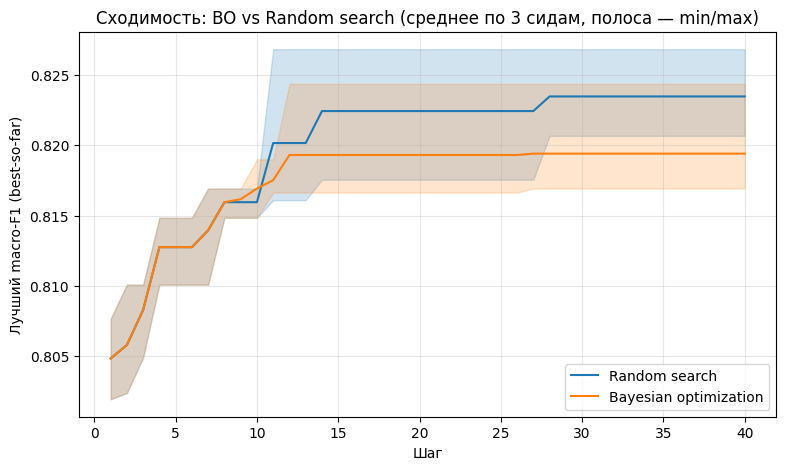

In [ ]:
def best_so_far(history):
    scores = [h["score"] for h in history]
    return np.maximum.accumulate(scores)

def mean_band(hist_dict, seeds):
    curves = np.array([best_so_far(hist_dict[s]) for s in seeds])
    return curves.mean(0), curves.min(0), curves.max(0)

r_mean, r_min, r_max = mean_band(hist_random, SEEDS)
b_mean, b_min, b_max = mean_band(hist_bo, SEEDS)
steps = np.arange(1, 41)

plt.figure(figsize=(9, 5))
plt.plot(steps, r_mean, label="Random search", color="tab:blue")
plt.fill_between(steps, r_min, r_max, alpha=0.2, color="tab:blue")
plt.plot(steps, b_mean, label="Bayesian optimization", color="tab:orange")
plt.fill_between(steps, b_min, b_max, alpha=0.2, color="tab:orange")
plt.xlabel("Шаг"); plt.ylabel("Лучший macro-F1 (best-so-far)")
plt.title("Сходимость: BO vs Random search (среднее по 3 сидам, полоса — min/max)")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig(f"{SAVE_DIR}/convergence.png", dpi=150)
plt.show()

BO с RF-суррогатом не показал преимущества над члучайным поиском. К сороковому шагу random в среднем дал 0.8235, BO-RF 0.8194 — разница около 0.004, в пределах шума val (стандартная ошибка macro-F1 на 1998 объектах примерно 0.009), но направление устойчивое: после 15-го шага random уже нигде не опускается ниже BO

In [ ]:
print("По val (best-so-far на 40-м шаге)")
for s in SEEDS:
    print(f"seed {s}: random={best_so_far(hist_random[s])[-1]:.4f}  bo={best_so_far(hist_bo[s])[-1]:.4f}")

def best_cfg(history):
    return max(history, key=lambda h: h["score"])["cfg"]

def test_score(cfg):
    m = CatBoostClassifier(**cfg, cat_features=cat_features, thread_count=-1,
                           random_seed=42, verbose=0)
    m.fit(X_train, y_train)
    return f1_score(y_test, m.predict(X_test).ravel(), average="macro")

print("\nНа test (лучшая конфигурация каждого метода/сида)")
for s in SEEDS:
    print(f"seed {s}: random_test={test_score(best_cfg(hist_random[s])):.4f}  "
          f"bo_test={test_score(best_cfg(hist_bo[s])):.4f}")

По val (best-so-far на 40-м шаге)
seed 0: random=0.8229  bo=0.8244
seed 1: random=0.8268  bo=0.8169
seed 2: random=0.8207  bo=0.8169

На test (лучшая конфигурация каждого метода/сида)
seed 0: random_test=0.8259  bo_test=0.8206
seed 1: random_test=0.8260  bo_test=0.8283
seed 2: random_test=0.8242  bo_test=0.8126


Сравнение по тестовой выборке показывает, что BO с RF-суррогатом не имеет преимущества над случайным поиском. Направление успеха метода не воспроизводится стабильно между val и test на 2 из 3 сидов, что говорит о том, что наблюдаемые различия в качестве (0.001–0.015) сопоставимы с шумом оценки на выборке такого размера, а не отражают реальное превосходство одного метода над другим

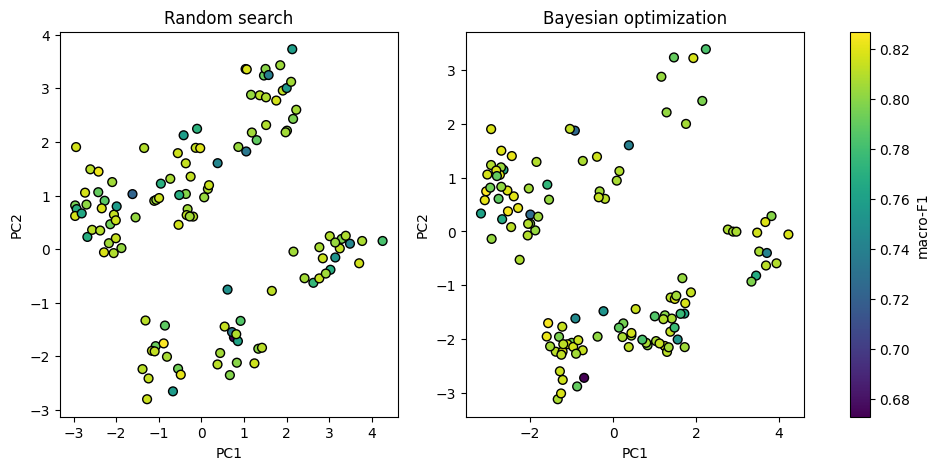

In [ ]:
def to_matrix(history):
    return np.array([encode(h["cfg"]) for h in history])

all_hist = sum(hist_random.values(), []) + sum(hist_bo.values(), [])
X_all = to_matrix(all_hist)
pca = make_pipeline(StandardScaler(), PCA(n_components=2, random_state=42)).fit(X_all)

def plot_space(ax, history, title):
    Xp = pca.transform(to_matrix(history))
    scores = [h["score"] for h in history]
    sc = ax.scatter(Xp[:, 0], Xp[:, 1], c=scores, cmap="viridis", s=40, edgecolor="k")
    ax.set_title(title); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
    return sc

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sc = plot_space(axes[0], sum(hist_random.values(), []), "Random search")
plot_space(axes[1], sum(hist_bo.values(), []), "Bayesian optimization")
fig.colorbar(sc, ax=axes, label="macro-F1")
plt.savefig(f"{SAVE_DIR}/hyperparam_space.png", dpi=150)
plt.show()

In [ ]:
p = pca.named_steps["pca"]
print("Доля объяснённой дисперсии:", p.explained_variance_ratio_.round(3),
      "сумма:", p.explained_variance_ratio_.sum().round(3))
load = pd.DataFrame(p.components_.T, index=NAMES, columns=["PC1", "PC2"])
print(load.reindex(load.abs().max(axis=1).sort_values(ascending=False).index).head(6).round(2))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Доля объяснённой дисперсии: [0.19  0.141] сумма: 0.331
                      PC1   PC2
subsample           -0.25  0.49
bootstrap_type      -0.24  0.48
bagging_temperature  0.26 -0.48
grow_policy          0.46  0.22
boosting_type       -0.40 -0.10
min_data_in_leaf     0.40  0.12


In [ ]:
cfgs = sum(hist_random.values(), []) + sum(hist_bo.values(), [])
Xp = pca.transform(X_all)
df = pd.DataFrame({"bootstrap": [h["cfg"]["bootstrap_type"] for h in cfgs],
                   "grow": [h["cfg"]["grow_policy"] for h in cfgs],
                   "PC1": Xp[:, 0], "PC2": Xp[:, 1]})
print(df.groupby("bootstrap")[["PC1", "PC2"]].mean().round(2))
print(df.groupby("grow")[["PC1", "PC2"]].mean().round(2))

            PC1   PC2
bootstrap            
Bayesian   0.98 -1.45
Bernoulli -0.66  0.95
MVS       -1.09  1.64
                PC1   PC2
grow                     
Depthwise      0.45 -0.48
Lossguide      2.46  1.28
SymmetricTree -1.90 -0.39


Первые две компоненты объясняют 33% дисперсии, и обе определяются в основном категориальными и условными гиперпараметрами. PC2 отражает bootstrap_type и связанные с ним subsample (+0.49) и bagging_temperature (−0.48). Средний PC2 у конфигураций с Bayesian bootstrap равен −1.45, с Bernoulli и MVS — 0.95 и 1.64

PC1 отражает политику роста дерева: grow_policy и зависящие от нее min_data_in_leaf и boosting_type. Средний PC1 у SymmetricTree равен −1.90, у Lossguide 2.46, Depthwise занимает промежуточное положение. Тип бутстрэпа тоже частично влияет на PC1, поэтому оси не полностью независимы. Точки группируются в кластеры, соответствующие комбинациям этих параметров: внизу Bayesian bootstrap, вверху Bernoulli/MVS, слева SymmetricTree, справа Lossguide. Числовые параметры, включая learning_rate, дают разброс внутри кластеров

Хорошие конфигурации (macro-F1 = 0.82) есть в каждом кластере, как и неудачные (0.70–0.75). Значит, выбор типа бутстрэпа и политики роста сам по себе не определяет качество. Это согласуется с оценкой важности, где доминирует learning_rate, который в данной проекции почти не представлен

Распределение точек у методов различается. Random search заполняет кластеры примерно равномерно. BO смещает выборку: больше точек внизу (Bayesian bootstrap) и в левом верхнем кластере (SymmetricTree с Bernoulli/MVS), заметно меньше в правом верхнем (Lossguide с Bernoulli/MVS). Суррогат действительно перераспределяет бюджет между областями пространства, но это не дало выигрыша. Плохие конфигурации встречаются и в предпочтенных BO областях (минимум BO-RF — macro-F1 = 0.68), а лучшее значение на val у BO в среднем по сидам ниже, чем у random search (0.819 против 0.824).

In [ ]:
def importance_report(history, title):
    X_h = to_matrix(history)
    y_h = np.array([h["score"] for h in history])
    rf = RandomForestRegressor(n_estimators=200, random_state=0).fit(X_h, y_h)
    order = np.argsort(rf.feature_importances_)[::-1]
    print(f"\n{title}")
    for i in order[:10]:
        print(f"{NAMES[i]:28s} {rf.feature_importances_[i]:.4f}")
    return rf.feature_importances_

imp_random = importance_report(sum(hist_random.values(), []), "Важность гиперпараметров (Random search)")
imp_bo = importance_report(sum(hist_bo.values(), []), "Важность гиперпараметров (Bayesian optimization)")


Важность гиперпараметров (Random search)
learning_rate                0.5741
random_strength              0.1096
iterations                   0.0722
model_size_reg               0.0497
rsm                          0.0370
l2_leaf_reg                  0.0228
feature_border_type          0.0222
one_hot_max_size             0.0214
min_data_in_leaf             0.0162
leaf_estimation_iterations   0.0142

Важность гиперпараметров (Bayesian optimization)
learning_rate                0.4589
iterations                   0.2216
random_strength              0.0812
depth                        0.0305
boosting_type                0.0258
rsm                          0.0225
model_size_reg               0.0190
border_count                 0.0175
min_data_in_leaf             0.0162
l2_leaf_reg                  0.0154


Оба метода определили learning_rate как доминирующий гиперпараметр, с большим отрывом от остальных

У random search на втором месте random_strength (0.11), а у BO iterations (0.22), заметно выше, чем у random (0.07). Возможно, BO чаще исследовал разные значения именно iterations в поисках лучшей конфигурации, тогда как random search покрывал пространство равномернее, и Random Forest на его истории увидел меньше сигнала от этого параметра

Важность считалась на истории поиска каждого метода отдельно (обучили Random Forest на парах «конфигурация → score» из истории random search и отдельно — из истории BO). Поэтому цифры не полностью сравнимы напрямую. Они отражают, что видела модель в своей конкретной выборке из 120 точек (3 сида по 40), а не истинную важность параметра в абсолютном смысле.

# Дополнительный эксперимент: GP-суррогат

Random Forest хуже экстраполирует неопределенность, чем гауссовский процесс

GP с простым RBF-ядром работает по тем же признакам, что и RF. Категориальные и условные параметры не получают честного категориального ядра, это упрощение, которое может ограничить качество GP на смешанном пространстве.

Отличия от RF-версии: признаки масштабируются (RBF чувствительно к масштабу), ядро — RBF + White (добавлено на случай шума), неопределенность σ(x) дает сам GP аналитически, а не разброс по деревьям. На практике оптимизатор ядра прижал уровень шума WhiteKernel к нижней границе (1e-5, см. предупреждения). Это ожидаемо: evaluate детерминирована (random_seed=42), и повторный запуск той же конфигурации даёт тот же macro-F1. Шума измерения в обычном смысле нет, поэтому GP фактически интерполирует наблюдения

In [ ]:
def gp_predict(gp, scaler, X):
    Xs = scaler.transform(X)
    mu, sigma = gp.predict(Xs, return_std=True)
    return mu, sigma

def run_bo_gp(n_steps=40, n_init=8, seed=0, n_cand=3000, path=None, init_hist=None):
    rng = np.random.default_rng(seed)
    cand_rng = np.random.default_rng(20_000 + seed)   # отдельный поток кандидатов, не пересекается с RF-версией
    history = []
    for i in range(n_steps):
        if init_hist is not None and i < n_init:
            history.append(init_hist[i]); continue
        if i < n_init:
            cfg = sample_config(rng)
        else:
            X_h = np.array([encode(h["cfg"]) for h in history])
            y_h = np.array([h["score"] for h in history])

            scaler = StandardScaler().fit(X_h)
            kernel = ConstantKernel(1.0) * RBF(length_scale=1.0) + WhiteKernel(noise_level=1e-3)
            gp = GaussianProcessRegressor(kernel=kernel, normalize_y=True,
                                          n_restarts_optimizer=3, random_state=seed)
            gp.fit(scaler.transform(X_h), y_h)

            cands = [sample_config(cand_rng) for _ in range(n_cand)]
            mu, sigma = gp_predict(gp, scaler, np.array([encode(c) for c in cands]))
            cfg = cands[int(np.argmax(expected_improvement(mu, sigma, y_h.max())))]
        t = time.time()
        try:
            score = float(evaluate(cfg))
        except Exception as e:
            print(f"  ошибка на шаге {i}: {str(e)[:100]}"); score = 0.0
        history.append({"step": i, "cfg": cfg, "score": score, "time": time.time() - t})
        if path:
            with open(path, "w") as f: json.dump(history, f)
        print(f"{i:3d} | {'init' if i < n_init else 'GP  '} | macro-F1={score:.4f} | best={max(h['score'] for h in history):.4f} | {history[-1]['time']:.0f} с")
    return history

In [ ]:
_real_evaluate = evaluate
try:
    evaluate = lambda cfg: float(np.random.rand())
    run_bo_gp(n_steps=12, n_init=8, seed=0)
finally:
    evaluate = _real_evaluate

  0 | init | macro-F1=0.3563 | best=0.3563 | 0 с
  1 | init | macro-F1=0.3440 | best=0.3563 | 0 с
  2 | init | macro-F1=0.4646 | best=0.4646 | 0 с
  3 | init | macro-F1=0.9685 | best=0.9685 | 0 с
  4 | init | macro-F1=0.7414 | best=0.9685 | 0 с
  5 | init | macro-F1=0.7424 | best=0.9685 | 0 с
  6 | init | macro-F1=0.2324 | best=0.9685 | 0 с
  7 | init | macro-F1=0.3671 | best=0.9685 | 0 с
  8 | GP   | macro-F1=0.0659 | best=0.9685 | 0 с
  9 | GP   | macro-F1=0.6351 | best=0.9685 | 0 с
 10 | GP   | macro-F1=0.6267 | best=0.9685 | 0 с
 11 | GP   | macro-F1=0.9382 | best=0.9685 | 0 с


In [ ]:
hist_gp = {}
hist_gp[0] = run_bo_gp(40, n_init=8, seed=0, path=f"{SAVE_DIR}/results_gp_seed0.json", init_hist=hist_random[0])

  8 | GP   | macro-F1=0.8133 | best=0.8161 | 36 с
  9 | GP   | macro-F1=0.8169 | best=0.8169 | 79 с
 10 | GP   | macro-F1=0.7909 | best=0.8169 | 60 с
 11 | GP   | macro-F1=0.8027 | best=0.8169 | 106 с
 12 | GP   | macro-F1=0.8077 | best=0.8169 | 4 с
 13 | GP   | macro-F1=0.8054 | best=0.8169 | 151 с
 14 | GP   | macro-F1=0.8115 | best=0.8169 | 9 с
 15 | GP   | macro-F1=0.8090 | best=0.8169 | 15 с
 16 | GP   | macro-F1=0.8196 | best=0.8196 | 55 с
 17 | GP   | macro-F1=0.8169 | best=0.8196 | 63 с
 18 | GP   | macro-F1=0.8120 | best=0.8196 | 51 с


/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


 19 | GP   | macro-F1=0.8146 | best=0.8196 | 87 с


/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


 20 | GP   | macro-F1=0.8187 | best=0.8196 | 118 с


...

 35 | GP   | macro-F1=0.8049 | best=0.8225 | 12 с


/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


 36 | GP   | macro-F1=0.8089 | best=0.8225 | 129 с


/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


 37 | GP   | macro-F1=0.8131 | best=0.8225 | 25 с
 38 | GP   | macro-F1=0.8144 | best=0.8225 | 63 с
 39 | GP   | macro-F1=0.8126 | best=0.8225 | 93 с


In [ ]:
hist_gp[1] = run_bo_gp(40, n_init=8, seed=1, path=f"{SAVE_DIR}/results_gp_seed1.json", init_hist=hist_random[1])

  8 | GP   | macro-F1=0.8050 | best=0.8148 | 18 с


/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


  9 | GP   | macro-F1=0.8190 | best=0.8190 | 23 с


/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


 10 | GP   | macro-F1=0.7998 | best=0.8190 | 18 с


/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


 11 | GP   | macro-F1=0.7971 | best=0.8190 | 38 с
 12 | GP   | macro-F1=0.8081 | best=0.8190 | 6 с
 13 | GP   | macro-F1=0.8123 | best=0.8190 | 10 с
 14 | GP   | macro-F1=0.8130 | best=0.8190 | 48 с
 15 | GP   | macro-F1=0.8021 | best=0.8190 | 20 с
 16 | GP   | macro-F1=0.8153 | best=0.8190 | 23 с
 17 | GP   | macro-F1=0.8171 | best=0.8190 | 20 с
 18 | GP   | macro-F1=0.8150 | best=0.8190 | 47 с
 19 | GP   | macro-F1=0.8094 | best=0.8190 | 82 с
 20 | GP   | macro-F1=0.8096 | best=0.8190 | 32 с
 21 | GP   | macro-F1=0.8212 | best=0.8212 | 165 с
 22 | GP   | macro-F1=0.8176 | best=0.8212 | 23 с
 23 | GP   | macro-F1=0.8169 | best=0.8212 | 33 с
 24 | GP   | macro-F1=0.8170 | best=0.8212 | 38 с
 25 | GP   | macro-F1=0.8144 | best=0.8212 | 31 с
 26 | GP   | macro-F1=0.8160 | best=0.8212 | 20 с
 27 | GP   | macro-F1=0.8191 | best=0.8212 | 42 с
 28 | GP   | macro-F1=0.8110 | best=0.8212 | 10 с
 29 | GP   | macro-F1=0.8104 | best=0.8212 | 18 с
 30 | GP   | macro-F1=0.8183 | best=0.8212 | 16 с


In [ ]:
hist_gp[2] = run_bo_gp(40, n_init=8, seed=2, path=f"{SAVE_DIR}/results_gp_seed2.json", init_hist=hist_random[2])

  8 | GP   | macro-F1=0.7848 | best=0.8169 | 20 с
  9 | GP   | macro-F1=0.7888 | best=0.8169 | 4 с
 10 | GP   | macro-F1=0.7254 | best=0.8169 | 5 с


/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


 11 | GP   | macro-F1=0.8167 | best=0.8169 | 33 с


/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


 12 | GP   | macro-F1=0.8172 | best=0.8172 | 13 с


...

 35 | GP   | macro-F1=0.8193 | best=0.8207 | 67 с


/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


 36 | GP   | macro-F1=0.8189 | best=0.8207 | 12 с


/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


 37 | GP   | macro-F1=0.8094 | best=0.8207 | 44 с
 38 | GP   | macro-F1=0.8085 | best=0.8207 | 12 с
 39 | GP   | macro-F1=0.7292 | best=0.8207 | 33 с


In [ ]:
hist_random = {s: json.load(open(f"{SAVE_DIR}/results_random_seed{s}.json")) for s in SEEDS}
hist_bo = {s: json.load(open(f"{SAVE_DIR}/results_bo_seed{s}.json")) for s in SEEDS}
hist_gp = {s: json.load(open(f"{SAVE_DIR}/results_gp_seed{s}.json")) for s in SEEDS}

for name, h in [("random", hist_random), ("bo", hist_bo), ("gp", hist_gp)]:
    print(name, {s: len(h[s]) for s in SEEDS})

random {0: 40, 1: 40, 2: 40}
bo {0: 40, 1: 40, 2: 40}
gp {0: 40, 1: 40, 2: 40}


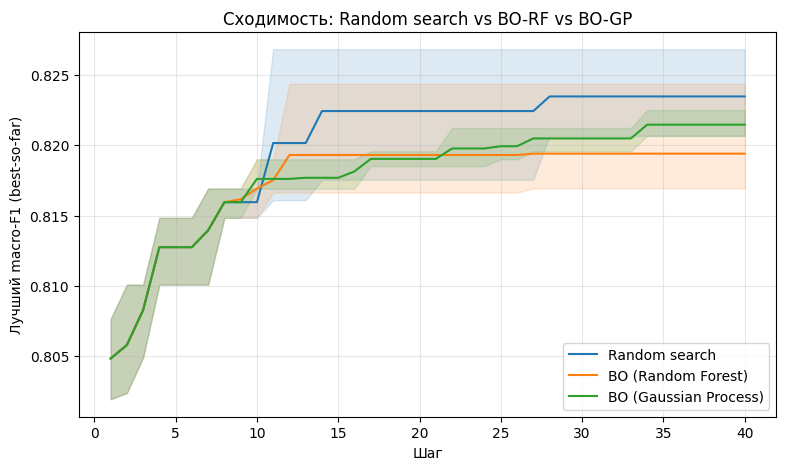

In [ ]:
def best_so_far(history):
    scores = [h["score"] for h in history]
    return np.maximum.accumulate(scores)

def mean_band(hist_dict, seeds):
    curves = np.array([best_so_far(hist_dict[s]) for s in seeds])
    return curves.mean(0), curves.min(0), curves.max(0)

r_mean, r_min, r_max = mean_band(hist_random, SEEDS)
b_mean, b_min, b_max = mean_band(hist_bo, SEEDS)
g_mean, g_min, g_max = mean_band(hist_gp, SEEDS)
steps = np.arange(1, 41)

plt.figure(figsize=(9, 5))
plt.plot(steps, r_mean, label="Random search", color="tab:blue")
plt.fill_between(steps, r_min, r_max, alpha=0.15, color="tab:blue")
plt.plot(steps, b_mean, label="BO (Random Forest)", color="tab:orange")
plt.fill_between(steps, b_min, b_max, alpha=0.15, color="tab:orange")
plt.plot(steps, g_mean, label="BO (Gaussian Process)", color="tab:green")
plt.fill_between(steps, g_min, g_max, alpha=0.15, color="tab:green")
plt.xlabel("Шаг"); plt.ylabel("Лучший macro-F1 (best-so-far)")
plt.title("Сходимость: Random search vs BO-RF vs BO-GP")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig(f"{SAVE_DIR}/convergence_all.png", dpi=150)
plt.show()

GP немного лучше RF по best-so-far к 40-му шагу (0.8215 против 0.8194), но разница в пределах шума, и оба уступают random search. RF выходит на плато к 12-му шагу, GP продолжает находить небольшие улучшения до примерно 34-го шага

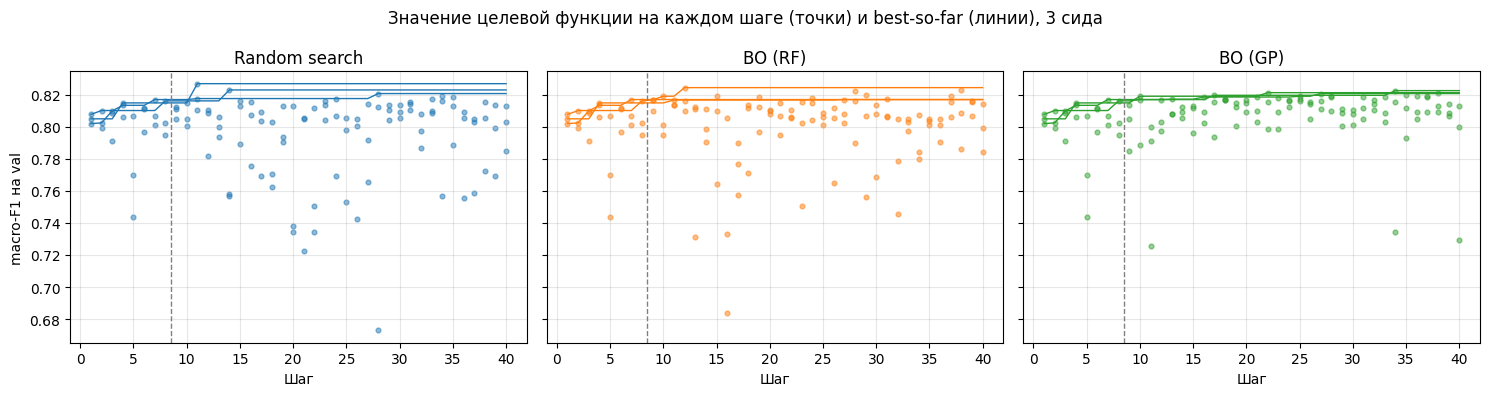

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (name, h, color) in zip(axes, [("Random search", hist_random, "tab:blue"),
                                        ("BO (RF)", hist_bo, "tab:orange"),
                                        ("BO (GP)", hist_gp, "tab:green")]):
    for s in SEEDS:
        ax.scatter(steps, [x["score"] for x in h[s]], s=12, alpha=0.5, color=color)
        ax.plot(steps, best_so_far(h[s]), color=color, lw=1)
    ax.axvline(8.5, ls="--", color="gray", lw=1)
    ax.set_title(name); ax.set_xlabel("Шаг"); ax.grid(alpha=0.3)
axes[0].set_ylabel("macro-F1 на val")
plt.suptitle("Значение целевой функции на каждом шаге (точки) и best-so-far (линии), 3 сида")
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/raw_scores.png", dpi=150)
plt.show()

Первые 8 шагов у всех методов совпадают (общая случайная инициализация, до пунктирной линии).

Random search равномерно исследует пространство. Его точки разбросаны от 0.67 до 0.83, и на шагах 9–40 ниже 0.78 оказываются где-то 20 конфигураций. BO-RF сужает разброс незначительно: 14 провалов ниже 0.78, и они встречаются до конца прогона. У BO-GP виначе. После 12 шага почти все его точки лежат в полосе 0.79–0.82, ниже 0.78 опускаются только 3 конфигурации, а средний macro-F1 предложенных точек выше, чем у random (0.808 против 0.795; медианы 0.812 и 0.805).

Таким образом, байесовская оптимизация, особенно с GP-суррогатом, действительно научилась избегать плохих областей и предлагать стабильно хорошие конфигурации

In [ ]:
print("По val (best-so-far на 40-м шаге)")
for s in SEEDS:
    print(f"seed {s}: random={best_so_far(hist_random[s])[-1]:.4f}  "
          f"bo_rf={best_so_far(hist_bo[s])[-1]:.4f}  bo_gp={best_so_far(hist_gp[s])[-1]:.4f}")

print("\nНа test (лучшая конфигурация BO-GP)")
test_gp = {s: test_score(best_cfg(hist_gp[s])) for s in SEEDS}
for s in SEEDS:
    print(f"seed {s}: bo_gp_test={test_gp[s]:.4f}")
print(f"mean bo_gp_test = {np.mean(list(test_gp.values())):.4f}")

По val (best-so-far на 40-м шаге)
seed 0: random=0.8229  bo_rf=0.8244  bo_gp=0.8225
seed 1: random=0.8268  bo_rf=0.8169  bo_gp=0.8212
seed 2: random=0.8207  bo_rf=0.8169  bo_gp=0.8207

На test (лучшая конфигурация BO-GP)
seed 0: bo_gp_test=0.8250
seed 1: bo_gp_test=0.8153
seed 2: bo_gp_test=0.8243
mean bo_gp_test = 0.8215


Средний best-so-far на val: random 0.8235, BO-GP 0.8215, BO-RF 0.8194. На test порядок тот же: 0.8254, 0.8215 и 0.8205 соответственно. BO-GP ни на одном сиде не обошел random (на seed 2 результаты совпали), зато его результаты стабильнее, чем у BO-RF: меньше разброс между сидами, и val совпадает с test. Все различия (≤0.005) меньше стандартной ошибки (~0.009), поэтому статистически лучшего метода здесь нет

In [ ]:
imp_random = importance_report(sum(hist_random.values(), []), "Важность гиперпараметров (Random search)")
imp_bo = importance_report(sum(hist_bo.values(), []), "Важность гиперпараметров (Bayesian optimization RF)")
imp_gp = importance_report(sum(hist_gp.values(), []), "Важность гиперпараметров (BO Gaussian Process)")


Важность гиперпараметров (Random search)
learning_rate                0.5741
random_strength              0.1096
iterations                   0.0722
model_size_reg               0.0497
rsm                          0.0370
l2_leaf_reg                  0.0228
feature_border_type          0.0222
one_hot_max_size             0.0214
min_data_in_leaf             0.0162
leaf_estimation_iterations   0.0142

Важность гиперпараметров (Bayesian optimization RF)
learning_rate                0.4589
iterations                   0.2216
random_strength              0.0812
depth                        0.0305
boosting_type                0.0258
rsm                          0.0225
model_size_reg               0.0190
border_count                 0.0175
min_data_in_leaf             0.0162
l2_leaf_reg                  0.0154

Важность гиперпараметров (BO Gaussian Process)
learning_rate                0.5400
random_strength              0.0993
rsm                          0.0830
l2_leaf_reg                  

Все три метода выбрали learning_rate в качестве ведущего гиперпараметра. При этом оценка важности для BO-GP заметно ближе к random search, чем к BO-RF: у BO-RF iterations выходит на второе место с большим отрывом (0.22), тогда как у BO-GP и random search второй по важности параметр — random_strength (0.10–0.11), а вклад iterations минимален. При этом по графику сырых значений GP, наоборот, сильнее всех концентрируется в хорошей области. Поэтому близость его важностей к random search объясняется не стратегией поиска, а тем, что на 120 точках оценка важности сама по себе нестабильна.

# Возможные причины таких итогов



* Размерность пространства против размер бюджета

Пространство состоит из 20 гиперпараметров (11 числовых + 3 категориальных + 6 условных, активных только при определенных значениях родительских параметров). После инициализации (8 точек) суррогату остается всего 32 шага, чтобы построить полезную модель зависимости оценки от конфигурации в таком многомерном пространстве.

* Приближенный поиск максимума функции улучшения

Максимизация EI по смешанному (числа + категории + условные параметры) пространству не имеет градиента, поэтому максимум искался приближенно — перебором 3000 случайных кандидатов из `sample_config`, а не точным оптимизатором. Значит, найденная точка — не гарантированный максимум EI, а лучшая среди случайной выборки. При 20 измерениях 3000 точек покрывают пространство существенно реже, чем в низкоразмерном случае, и вероятность пропустить действительно перспективную область растет

* Упрощенное кодирование категориальных и условных параметров

Категориальные параметры (`bootstrap_type`, `grow_policy` и др.) кодировались номером в списке допустимых значений, а неактивные условные параметры (например, `bagging_temperature` при `bootstrap_type != "Bayesian"`) получали фиксированное значение −1. Оба суррогата (RF и особенно GP с RBF-ядром) опираются на понятие расстояния или разбиения по значению признака — а номер категории не несет содержательного порядка (категория 2 не «ближе» к категории 1, чем к категории 0), и −1 у неактивного параметра может ошибочно восприниматься как «маленькое значение», а не как «параметр не участвует». Особенно чувствительно к этому RBF-ядро GP, которое явно оперирует евклидовым расстоянием между точками — это может частично объяснять, почему GP-суррогат, несмотря на теоретически лучшую оценку неопределённости, все равно не смог убедительно обойти random search

# Контрольный эксперимент

Определим топ-признаков для того, чтобы урезать пространство до 6 самых важных гиперпараметров

In [ ]:
imp_df = pd.DataFrame({"random": imp_random, "bo_rf": imp_bo, "bo_gp": imp_gp}, index=NAMES)
imp_df["mean"] = imp_df.mean(axis=1)
imp_df.sort_values("mean", ascending=False).head(10)

In [ ]:
top_features = ["learning_rate", "random_strength", "iterations",
                "rsm", "model_size_reg", "l2_leaf_reg"]

SPACE_SMALL = {k: SPACE[k] for k in top_features}

FIXED = {
    "depth": 6, "border_count": 128,
    "leaf_estimation_iterations": 3, "one_hot_max_size": 8,
    "max_ctr_complexity": 2, "bootstrap_type": "Bayesian",
    "grow_policy": "SymmetricTree", "boosting_type": "Plain",
    "feature_border_type": "GreedyLogSum", "sampling_frequency": "PerTree",
    "bagging_temperature": 0.5,
}

def sample_config_small(rng):
    cfg = dict(FIXED)
    cfg.update({n: sample_one(s, rng) for n, s in SPACE_SMALL.items()})
    return cfg

def evaluate_small(cfg):
    assert set(cfg.keys()) == set(FIXED) | set(SPACE_SMALL), "конфиг неполный"
    return evaluate(cfg)

In [ ]:
def run_random_small(n_steps, seed, path):
    rng = np.random.default_rng(seed)
    history = []
    for i in range(n_steps):
        cfg = sample_config_small(rng)
        t = time.time()
        try:
            score = float(evaluate_small(cfg))
        except Exception as e:
            print(f"  ошибка на шаге {i}: {str(e)[:100]}"); score = 0.0
        history.append({"step": i, "cfg": cfg, "score": score, "time": time.time() - t})
        with open(path, "w") as f:
            json.dump(history, f)
        print(f"{i:3d} | macro-F1={score:.4f} | best={max(h['score'] for h in history):.4f} | {history[-1]['time']:.0f} с")
    return history

#hist_random_small = run_random_small(40, seed=0, path=f"{SAVE_DIR}/results_random_small.json")

In [ ]:
def rf_predict(rf, X):
    p = np.stack([t.predict(X) for t in rf.estimators_])   # (деревья, кандидаты)
    return p.mean(0), p.std(0)

def run_bo_small(n_steps=40, n_init=8, seed=0, n_cand=3000, path=None):
    rng = np.random.default_rng(seed)
    cand_rng = np.random.default_rng(30_000 + seed)   # отдельный поток, не пересекается с прошлыми экспериментами
    history = []
    for i in range(n_steps):
        if i < n_init:
            cfg = sample_config_small(rng)
        else:
            X_h = np.array([encode(h["cfg"]) for h in history])
            y_h = np.array([h["score"] for h in history])
            rf = RandomForestRegressor(n_estimators=100, random_state=seed).fit(X_h, y_h)
            cands = [sample_config_small(cand_rng) for _ in range(n_cand)]
            mu, sigma = rf_predict(rf, np.array([encode(c) for c in cands]))
            cfg = cands[int(np.argmax(expected_improvement(mu, sigma, y_h.max())))]
        t = time.time()
        try:
            score = float(evaluate_small(cfg))
        except Exception as e:
            print(f"  ошибка на шаге {i}: {str(e)[:100]}"); score = 0.0
        history.append({"step": i, "cfg": cfg, "score": score, "time": time.time() - t})
        if path:
            with open(path, "w") as f: json.dump(history, f)
        print(f"{i:3d} | {'init' if i < n_init else 'BO  '} | macro-F1={score:.4f} | best={max(h['score'] for h in history):.4f} | {history[-1]['time']:.0f} с")
    return history

#hist_bo_small = run_bo_small(40, n_init=8, seed=0, path=f"{SAVE_DIR}/results_bo_small.json")

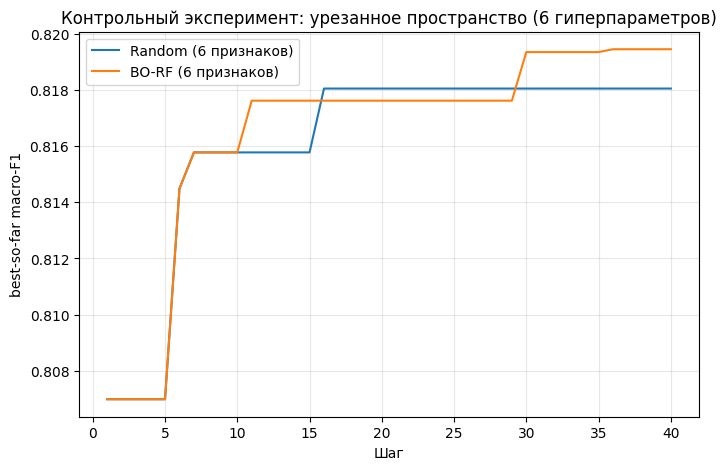

random-small best: 0.8180511147189362
bo-small best: 0.8194521628512698


In [ ]:
def bs(h): return np.maximum.accumulate([x["score"] for x in h])

plt.figure(figsize=(8,5))
plt.plot(range(1,41), bs(hist_random_small), label="Random (6 признаков)")
plt.plot(range(1,41), bs(hist_bo_small), label="BO-RF (6 признаков)")
plt.xlabel("Шаг"); plt.ylabel("best-so-far macro-F1")
plt.title("Контрольный эксперимент: урезанное пространство (6 гиперпараметров)")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

print("random-small best:", bs(hist_random_small)[-1])
print("bo-small best:", bs(hist_bo_small)[-1])

На урезанном пространстве BO-RF к 40-му шагу немного выше random search: 0.8194 против 0.8181 (разница 0.0014, меньше шума val 0.009). Преимущество неустойчиво: на шагах 16–29 впереди был random. Эксперимент выполнен на одном сиде, поэтому вывод предварительный. Обе оценки ниже, чем на полном пространстве (random в среднем 0.8235): фиксация 14 параметров стоила качества больше, чем дало сокращение размерности

# optuna

Границы совпадают со SPACE, а условия с is_active

In [ ]:
def objective(trial):
    cfg = {}
    cfg["iterations"]  = trial.suggest_int("iterations", 100, 500)
    cfg["learning_rate"] = trial.suggest_float("learning_rate", 0.01, 0.3, log=True)
    cfg["depth"] = trial.suggest_int("depth", 4, 8)
    cfg["l2_leaf_reg"] = trial.suggest_float("l2_leaf_reg", 1.0, 20.0, log=True)
    cfg["random_strength"] = trial.suggest_float("random_strength", 0.1, 10.0, log=True)
    cfg["border_count"] = trial.suggest_int("border_count", 32, 255)
    cfg["rsm"] = trial.suggest_float("rsm", 0.3, 1.0)
    cfg["model_size_reg"] = trial.suggest_float("model_size_reg", 0.0, 5.0)
    cfg["leaf_estimation_iterations"] = trial.suggest_int("leaf_estimation_iterations", 1, 10)
    cfg["one_hot_max_size"] = trial.suggest_int("one_hot_max_size", 2, 16)
    cfg["max_ctr_complexity"] = trial.suggest_int("max_ctr_complexity", 1, 4)
    cfg["feature_border_type"] = trial.suggest_categorical(
        "feature_border_type",
        ["GreedyLogSum", "Median", "Uniform", "UniformAndQuantiles", "MaxLogSum", "MinEntropy"])

    cfg["bootstrap_type"] = trial.suggest_categorical("bootstrap_type", ["Bayesian", "Bernoulli", "MVS"])
    if cfg["bootstrap_type"] == "Bayesian":
        cfg["bagging_temperature"] = trial.suggest_float("bagging_temperature", 0.0, 1.0)
    else:
        cfg["subsample"] = trial.suggest_float("subsample", 0.5, 1.0)

    cfg["grow_policy"] = trial.suggest_categorical("grow_policy", ["SymmetricTree", "Depthwise", "Lossguide"])
    if cfg["grow_policy"] == "SymmetricTree":
        cfg["boosting_type"] = trial.suggest_categorical("boosting_type", ["Plain", "Ordered"])
    if cfg["grow_policy"] in ("Depthwise", "Lossguide"):
        cfg["min_data_in_leaf"] = trial.suggest_int("min_data_in_leaf", 1, 50)
    if cfg["grow_policy"] == "Lossguide":
        cfg["max_leaves"] = trial.suggest_int("max_leaves", 8, 64)
    if cfg["grow_policy"] != "Lossguide":
        cfg["sampling_frequency"] = trial.suggest_categorical("sampling_frequency", ["PerTree", "PerTreeLevel"])

    return evaluate(cfg)

In [ ]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

def run_optuna(sampler_cls, seed, n_trials=40, n_init=8, init_hist=None, path=None):
    sampler = sampler_cls(seed=seed) if sampler_cls is optuna.samplers.RandomSampler \
              else sampler_cls(seed=seed, n_startup_trials=n_init)
    study = optuna.create_study(direction="maximize", sampler=sampler)

    if init_hist is not None:
        for h in init_hist[:n_init]:
            study.enqueue_trial(h["cfg"])

    study.optimize(objective, n_trials=n_trials)

    hist = [{"step": i, "cfg": t.params, "score": t.value,
             "time": (t.datetime_complete - t.datetime_start).total_seconds()}
            for i, t in enumerate(study.trials)]
    if path:
        json.dump(hist, open(path, "w"))
    return study, hist

hist_optuna_tpe, hist_optuna_rand = {}, {}
studies_tpe, studies_rand = {}, {}

for s in SEEDS:
    studies_tpe[s], hist_optuna_tpe[s] = run_optuna(
        optuna.samplers.TPESampler, seed=s, init_hist=hist_random[s],
        path=f"{SAVE_DIR}/results_optuna_tpe_seed{s}.json")

for s in SEEDS:
    studies_rand[s], hist_optuna_rand[s] = run_optuna(
        optuna.samplers.RandomSampler, seed=s, init_hist=hist_random[s],
        path=f"{SAVE_DIR}/results_optuna_random_seed{s}.json")

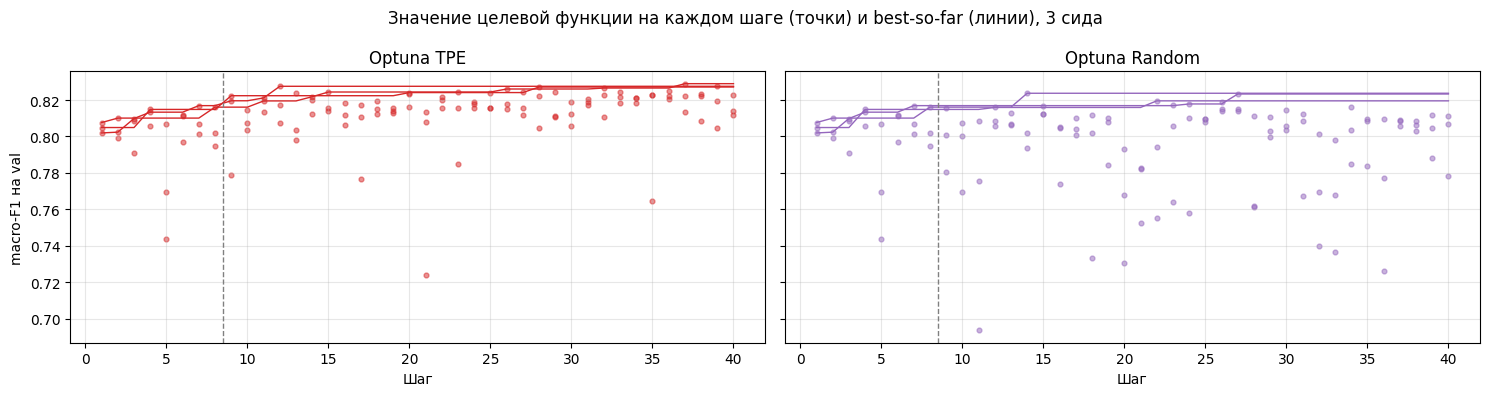

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
for ax, (name, h, color) in zip(axes, [("Optuna TPE", hist_optuna_tpe, "tab:red"),
                                        ("Optuna Random", hist_optuna_rand, "tab:purple")]):
    for s in SEEDS:
        ax.scatter(steps, [x["score"] for x in h[s]], s=12, alpha=0.5, color=color)
        ax.plot(steps, best_so_far(h[s]), color=color, lw=1)
    ax.axvline(8.5, ls="--", color="gray", lw=1)
    ax.set_title(name); ax.set_xlabel("Шаг"); ax.grid(alpha=0.3)
axes[0].set_ylabel("macro-F1 на val")
plt.suptitle("Значение целевой функции на каждом шаге (точки) и best-so-far (линии), 3 сида")
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/raw_scores_optuna.png", dpi=150)
plt.show()

Точки Optuna Random разбросаны от 0.69 до 0.82, и провалы ниже 0.78 встречаются на протяжении всего прогона. TPE после 8-го шага почти все время предлагает конфигурации в полосе 0.80–0.83, ниже 0.78 опускаются лишь единичные точки. По устойчивости предложений TPE похож на BO-GP, но, в отличие от него, продолжает находить улучшения до конца бюджета (последнее — около 37-го шага). В итоге его best-so-far на val выше, чем у всех остальных методов

In [ ]:
print("Optuna: По val (best-so-far на 40-м шаге)")
for s in SEEDS:
    print(f"seed {s}: tpe={best_so_far(hist_optuna_tpe[s])[-1]:.4f}  random={best_so_far(hist_optuna_rand[s])[-1]:.4f}")

print("\nOptuna: На test (лучшая конфигурация каждого метода/сида)")
for s in SEEDS:
    print(f"seed {s}: tpe_test={test_score(best_cfg(hist_optuna_tpe[s])):.4f}  "
          f"random_test={test_score(best_cfg(hist_optuna_rand[s])):.4f}")

Optuna: По val (best-so-far на 40-м шаге)
seed 0: tpe=0.8290  random=0.8237
seed 1: tpe=0.8271  random=0.8196
seed 2: tpe=0.8275  random=0.8233

Optuna: На test (лучшая конфигурация каждого метода/сида)
seed 0: tpe_test=0.8196  random_test=0.8264
seed 1: tpe_test=0.8272  random_test=0.8247
seed 2: tpe_test=0.8165  random_test=0.8275


Несмотря на стабильное преимущество Optuna TPE над Optuna Random на val (во всех 3х сидах), это преимущество не подтверждается на независимой тестовой выборке: TPE проигрывает Random на 2 из 3 сидов, иногда с большим отрывом (до 0.011). Это говорит о том, что более эффективный поиск TPE находит конфигурации, лучше подстроенные под val-выборку, но не обязательно лучше обобщающиеся — классический риск отбора лучшей гиперпараметрической конфигурации по единственной валидационной оценке при небольшом размере выборки

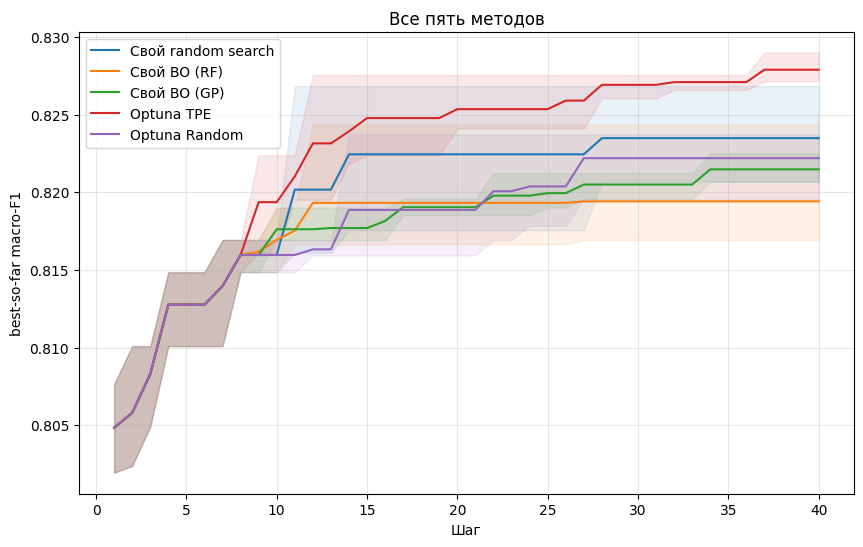

In [ ]:
r_mean, r_min, r_max = mean_band(hist_random, SEEDS)
b_mean, b_min, b_max = mean_band(hist_bo, SEEDS)
g_mean, g_min, g_max = mean_band(hist_gp, SEEDS)
tpe_mean, tpe_min, tpe_max = mean_band(hist_optuna_tpe, SEEDS)
rnd_mean, rnd_min, rnd_max = mean_band(hist_optuna_rand, SEEDS)

plt.figure(figsize=(10, 6))
for mean, mn, mx, label, color in [
    (r_mean, r_min, r_max, "Свой random search", "tab:blue"),
    (b_mean, b_min, b_max, "Свой BO (RF)", "tab:orange"),
    (g_mean, g_min, g_max, "Свой BO (GP)", "tab:green"),
    (tpe_mean, tpe_min, tpe_max, "Optuna TPE", "tab:red"),
    (rnd_mean, rnd_min, rnd_max, "Optuna Random", "tab:purple"),
]:
    plt.plot(steps, mean, label=label, color=color)
    plt.fill_between(steps, mn, mx, alpha=0.1, color=color)
plt.xlabel("Шаг"); plt.ylabel("best-so-far macro-F1")
plt.title("Все пять методов")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig(f"{SAVE_DIR}/convergence_full.png", dpi=150)
plt.show()

Optuna TPE — единственный метод, который устойчиво обходит остальных на val: к 40-му шагу его best-so-far 0.8279 против 0.8235 у собственного random search и 0.8222 у Optuna Random. Разрыв (0.004–0.006) меньше шума val (~0.009), но направление устойчивое: начиная с 9-го шага TPE нигде не опускается ниже других методов, тогда как кривые собственных RF/GP-версий пересекались с random. Два случайных поиска (собственный и Optuna) при общей инициализации разошлись на 0.0013, что соответствует обычной дисперсии случайного поиска на 3 сидах

In [ ]:
def to_matrix(history):
    return np.array([encode(h["cfg"]) for h in history])

all_hist = sum(hist_random.values(), []) + sum(hist_bo.values(), [])
X_all = to_matrix(all_hist)
pca = make_pipeline(StandardScaler(), PCA(n_components=2, random_state=42)).fit(X_all)

def plot_space(ax, history, title):
    Xp = pca.transform(to_matrix(history))
    scores = [h["score"] for h in history]
    sc = ax.scatter(Xp[:, 0], Xp[:, 1], c=scores, cmap="viridis", s=40, edgecolor="k")
    ax.set_title(title); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
    return sc

In [ ]:
pca_optuna = make_pipeline(StandardScaler(), PCA(n_components=2, random_state=42)).fit(
    to_matrix(sum(hist_optuna_tpe.values(), []) + sum(hist_optuna_rand.values(), [])))

def plot_space_optuna(ax, history, title):
    Xp = pca_optuna.transform(to_matrix(history))
    scores = [h["score"] for h in history]
    sc = ax.scatter(Xp[:, 0], Xp[:, 1], c=scores, cmap="viridis", s=40, edgecolor="k")
    ax.set_title(title); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
    return sc

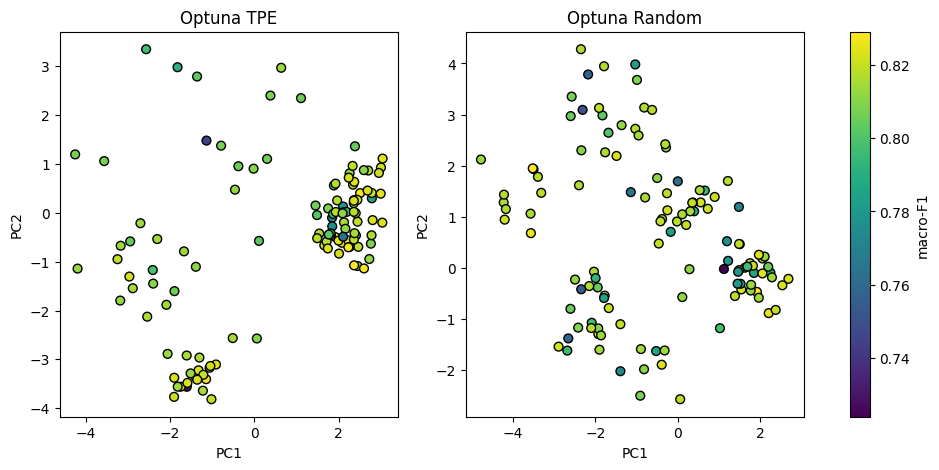

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sc = plot_space_optuna(axes[0], sum(hist_optuna_tpe.values(), []), "Optuna TPE")
plot_space_optuna(axes[1], sum(hist_optuna_rand.values(), []), "Optuna Random")
fig.colorbar(sc, ax=axes, label="macro-F1")
plt.savefig(f"{SAVE_DIR}/hyperparam_space_optuna.png", dpi=150)
plt.show()

In [ ]:
cfgs = sum(hist_optuna_tpe.values(), []) + sum(hist_optuna_rand.values(), [])
X_opt = to_matrix(cfgs)

# доля дисперсии и главные нагрузки
p = pca_optuna.named_steps["pca"]
print("Доля объяснённой дисперсии:", p.explained_variance_ratio_.round(3),
      "сумма:", p.explained_variance_ratio_.sum().round(3))
load = pd.DataFrame(p.components_.T, index=NAMES, columns=["PC1", "PC2"])
print(load.reindex(load.abs().max(axis=1).sort_values(ascending=False).index).head(6).round(2))

# средние координаты групп
Xp = pca_optuna.transform(X_opt)
df = pd.DataFrame({"method": ["TPE"] * 120 + ["Random"] * 120,
                   "bootstrap": [h["cfg"]["bootstrap_type"] for h in cfgs],
                   "grow": [h["cfg"]["grow_policy"] for h in cfgs],
                   "PC1": Xp[:, 0], "PC2": Xp[:, 1]})
print("\n", df.groupby("bootstrap")[["PC1", "PC2"]].mean().round(2))
print("\n", df.groupby("grow")[["PC1", "PC2"]].mean().round(2))

# какие комбинации выбирал TPE, а какие Random
print("\n", pd.crosstab([df["bootstrap"], df["grow"]], df["method"]))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Доля объяснённой дисперсии: [0.21 0.14] сумма: 0.351
                      PC1   PC2
bootstrap_type       0.39  0.27
grow_policy         -0.36  0.38
subsample            0.36  0.34
bagging_temperature -0.35 -0.34
max_leaves          -0.25  0.34
boosting_type        0.33 -0.29

             PC1   PC2
bootstrap            
Bayesian  -2.14 -1.31
Bernoulli -0.13  1.13
MVS        1.56  0.49

                 PC1   PC2
grow                     
Depthwise     -1.22  0.10
Lossguide     -2.44  2.44
SymmetricTree  1.32 -0.73

 method                   Random  TPE
bootstrap grow                      
Bayesian  Depthwise          21   16
          Lossguide          12    2
          SymmetricTree       8   22
Bernoulli Depthwise          12    4
          Lossguide          11    2
          SymmetricTree      12    3
MVS       Depthwise          12    5
          Lossg

Проекция объясняет 35% дисперсии (21% и 14%), главные компоненты снова определяются категориальными и условными параметрами: типом бутстрэпа, политикой роста дерева и зависящими от них subsample, bagging_temperature, max_leaves и boosting_type. Плотный правый кластер соответствует MVS + SymmetricTree (средний PC1 у MVS 1.56, у SymmetricTree 1.32).

TPE заметно сужает поиск. Из 120 его конфигураций 65 (54%) приходятся на комбинацию MVS + SymmetricTree, у Optuna Random их 23. Вторая предпочитаемая область — Bayesian bootstrap с SymmetricTree или Depthwise (38 конфигураций). Lossguide TPE практически отбросил: 5 конфигураций против 32 у Random. Optuna Random распределяет конфигурации по всем девяти комбинациям без выраженного предпочтения (8–23 на комбинацию). Следовательно, TPE быстро определил перспективную комбинацию категориальных параметров и сосредоточил на ней бюджет. Это дало стабильно высокие значения и лучший best-so-far на val, но не улучшило результат на test

In [ ]:
imp_tpe = importance_report(sum(hist_optuna_tpe.values(), []), "Важность гиперпараметров (Optuna TPE)")
imp_rand_o = importance_report(sum(hist_optuna_rand.values(), []), "Важность гиперпараметров (Optuna Random)")


Важность гиперпараметров (Optuna TPE)
learning_rate                0.6131
iterations                   0.0934
boosting_type                0.0739
random_strength              0.0299
one_hot_max_size             0.0268
model_size_reg               0.0232
depth                        0.0226
rsm                          0.0216
border_count                 0.0167
leaf_estimation_iterations   0.0166

Важность гиперпараметров (Optuna Random)
learning_rate                0.5004
random_strength              0.1394
depth                        0.1008
iterations                   0.0984
rsm                          0.0298
min_data_in_leaf             0.0218
l2_leaf_reg                  0.0208
border_count                 0.0204
model_size_reg               0.0148
one_hot_max_size             0.0115


Обе версии Optuna подтверждают ведущую роль learning_rate (0.61 у TPE, 0.50 у Random). Дальше важности распределены по-разному. У TPE заметный вклад получает boosting_type (0.07): TPE сосредоточился на SymmetricTree, где этот параметр активен. У Optuna Random вес распределён между random_strength, depth и iterations (0.10–0.14). Это согласуется с тем, что TPE сужает поиск до определённых значений категориальных параметров, а случайный поиск исследует пространство равномерно

In [ ]:
for s in SEEDS:
    print(f"seed {s}, TPE, optuna.importance")
    print(optuna.importance.get_param_importances(studies_tpe[s]))

seed 0, TPE, optuna.importance
{'l2_leaf_reg': 0.21380855854722203, 'model_size_reg': 0.149336293190842, 'leaf_estimation_iterations': 0.12959287826824042, 'one_hot_max_size': 0.11304154998180435, 'learning_rate': 0.09474497855830903, 'rsm': 0.07760256096388424, 'subsample': 0.06417716879385904, 'random_strength': 0.05153171031327255, 'border_count': 0.027845027025527384, 'depth': 0.02103179304352916, 'iterations': 0.020968903569784234, 'sampling_frequency': 0.014134955438821957, 'feature_border_type': 0.009308173324413986, 'grow_policy': 0.007470477447657384, 'max_ctr_complexity': 0.00276980311122569, 'bootstrap_type': 0.0026104252763808635, 'boosting_type': 2.4743145225730364e-05, 'bagging_temperature': 0.0, 'min_data_in_leaf': 0.0, 'max_leaves': 0.0}
seed 1, TPE, optuna.importance
{'model_size_reg': 0.6075854502073983, 'iterations': 0.11108126491721794, 'learning_rate': 0.06361734725091794, 'rsm': 0.058157898010610665, 'border_count': 0.02248163838918381, 'max_ctr_complexity': 0.019

/tmp/ipykernel_845/232883507.py:3: UserWarning: Some regimes for parameter `max_leaves` have less than 2 trials. The importance of the parameter may be inaccurate.
  print(optuna.importance.get_param_importances(studies_tpe[s]))
/tmp/ipykernel_845/232883507.py:3: UserWarning: Some regimes for parameter `subsample` have less than 2 trials. The importance of the parameter may be inaccurate.
  print(optuna.importance.get_param_importances(studies_tpe[s]))
/tmp/ipykernel_845/232883507.py:3: UserWarning: Some regimes for parameter `bagging_temperature` have less than 2 trials. The importance of the parameter may be inaccurate.
  print(optuna.importance.get_param_importances(studies_tpe[s]))
/tmp/ipykernel_845/232883507.py:3: UserWarning: Some regimes for parameter `sampling_frequency` have less than 2 trials. The importance of the parameter may be inaccurate.
  print(optuna.importance.get_param_importances(studies_tpe[s]))


Сравнение двух методик оценки важности выявило нестабильность. Собственная RF-оценка на объединённой истории (120 точек) называет learning_rate лидером во всех пяти случаях. Встроенная fANOVA Optuna, посчитанная по каждому сиду отдельно (40 точек), ставит на первое место три разных параметра: l2_leaf_reg (seed 0), model_size_reg (seed 1) и learning_rate (seed 2). При этом model_size_reg входит в топ-3 fANOVA на всех сидах, но ни в одной RF-оценке

Это подчеркивает риск делать далекоидущие выводы о важности гиперпараметров по малому числу наблюдений, особенно в условном пространстве, где часть параметров активна лишь у подмножества конфигураций (что подтверждают и явные предупреждения Optuna о недостаточном числе наблюдений для max_leaves, subsample, bagging_temperature, sampling_frequency).

# Выводы

* Реализованы случайный поиск и байесовская оптимизация (суррогаты: случайный лес и гауссовский процесс, функция улучшения EI) для CatBoost с 20 гиперпараметрами, включая категориальные и условные. Задача: классификация 10 жанров Spotify, целевая функция: macro-F1 на валидации. Бюджет 40 шагов, из них 8 общих случайных точек, 3 сида. Затем сравнение повторено с Optuna (TPE и RandomSampler).

* Сходимость. Средний best-so-far на val к 40-му шагу: Optuna TPE 0.8279, random search 0.8235, Optuna Random 0.8222, BO-GP 0.8215, BO-RF 0.8194. Собственная BO не превзошла случайный поиск ни с одним суррогатом. TPE получился единственным методом, который опережает остальные на всех сидах. При этом все различия (≤0.006) меньше стандартной ошибки macro-F1 (~0.009).

* Поведение методов. Байесовские методы действительно учатся: BO-GP и TPE после инициализации почти перестают предлагать плохие конфигурации (у BO-GP 3 точки ниже 0.78 против 21 у random), а TPE сосредотачивает больше половины бюджета на комбинации MVS + SymmetricTree. Но концентрация в хорошей области повышает средний, а не максимальный результат, поэтому по best-so-far собственная BO random search не обошла.

* Проверка на test. Порядок методов на test не сохранился: случайные поиски дали 0.8254 и 0.8262, а BO-RF, BO-GP и TPE — 0.8205–0.8215. Преимущество TPE на val оказалось подстройкой под валидационную выборку.

* Пространство и важность. Проекция PCA показала, что структура пространства определяется категориальными и условными параметрами (тип бутстрэпа, политика роста дерева), но хорошие конфигурации есть во всех кластерах. По всем методам доминирует learning_rate (0.46–0.61 по RF-оценке), далее iterations и random_strength. Оценки fANOVA по отдельным сидам нестабильны, что показывает ненадежность важностей на 40 наблюдениях

При малом бюджете, шумной метрике и высокой размерности смешанного пространства преимущество байесовской оптимизации над случайным поиском не гарантировано. Вероятные причины слабости собственной BO: приближенная максимизация EI по случайным кандидатам, порядковое кодирование категорий и условных параметров, шум целевой функции, сопоставимый с искомыми улучшениями. Для надежного сравнения нужно больше сидов, кросс-валидация вместо одного val-сплита и специализированные ядра для категориальных параметров